# 03 - Evaluation, explainability and the business case
> **All data in this notebook is synthetic.** It was generated by `src/generate_data.py` from assumptions chosen by the author. Findings demonstrate methodology, not real-world evidence.

In [1]:
import sys, json; sys.path.insert(0, "..")
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import config as C
pd.set_option("display.max_columns", 50); pd.set_option("display.precision", 3)
FIG = C.FIGURES
from src import business as B
b = json.load(open(C.REPORTS / 'business_results.json'))

## 1. Gains, lift and calibration

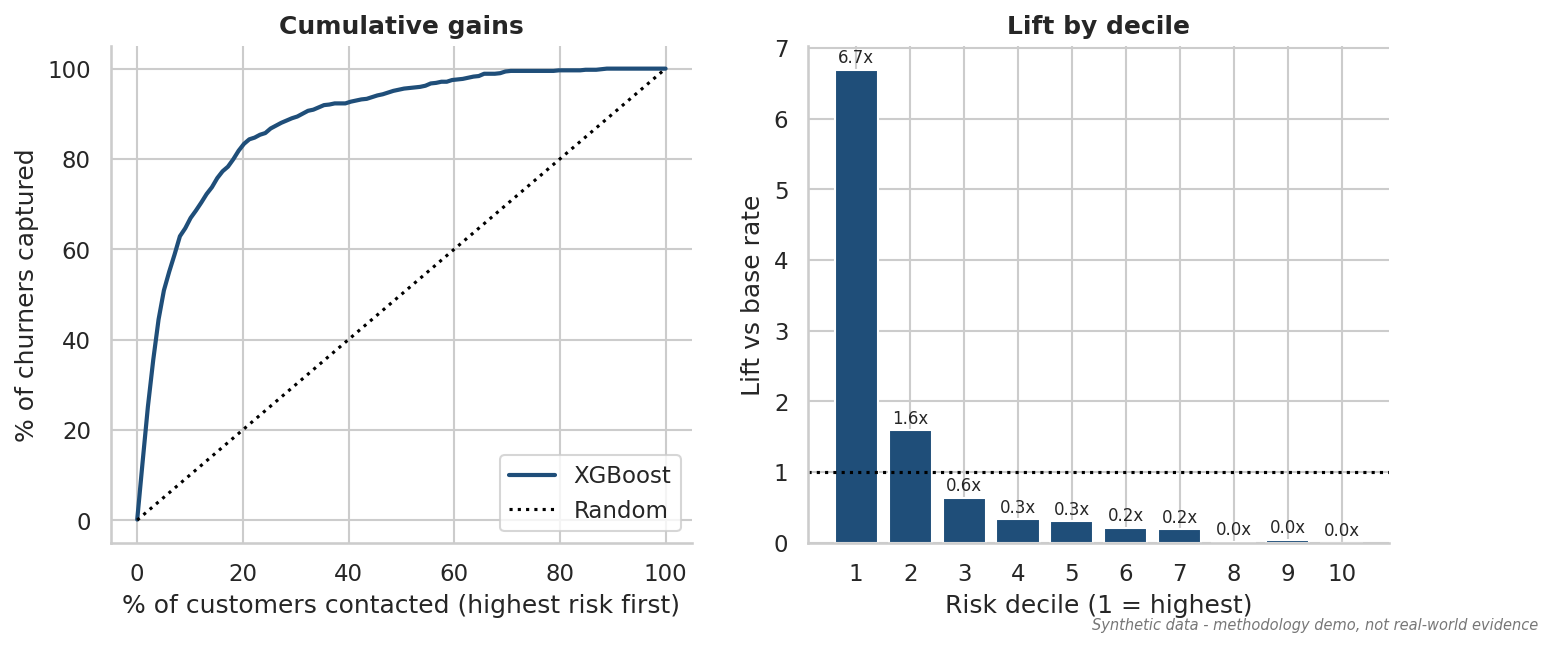

{'1': 6.69, '2': 1.59, '3': 0.63, '4': 0.33, '5': 0.3, '6': 0.21, '7': 0.19, '8': 0.01, '9': 0.04, '10': 0.0}


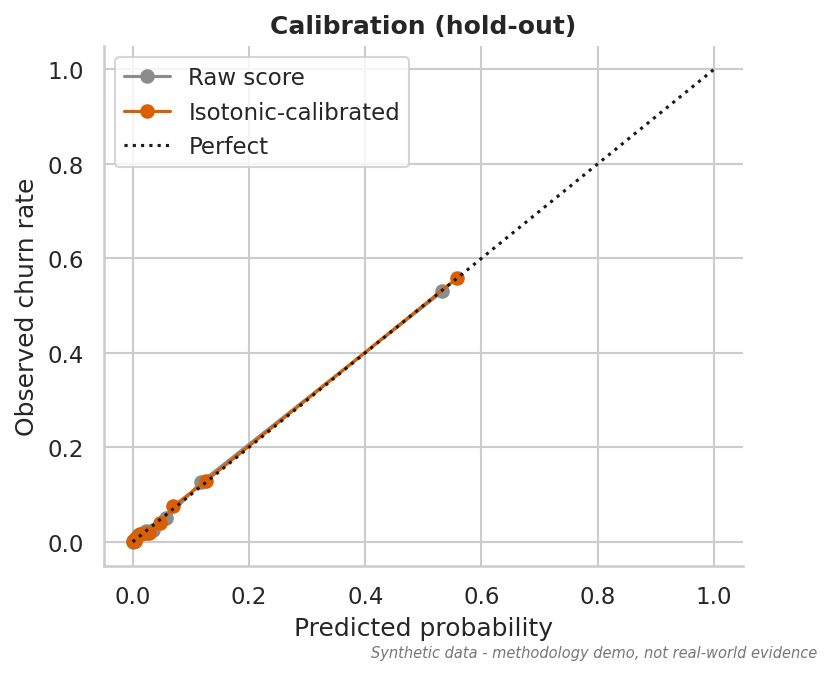

In [2]:
display(Image(FIG / 'model_gains_lift.png'))
print({k: round(v, 2) for k, v in b['lift_by_decile'].items()})
display(Image(FIG / 'model_calibration.png'))

The top risk decile contains ~6.7x the average churn rate; the bottom three deciles contain almost no churners, so these customers can be excluded from campaigns entirely. The isotonic calibrator brings predicted probabilities in line with observed churn (needed because the expected-value rule multiplies a probability by dollars).

## 2. Explainability (SHAP)

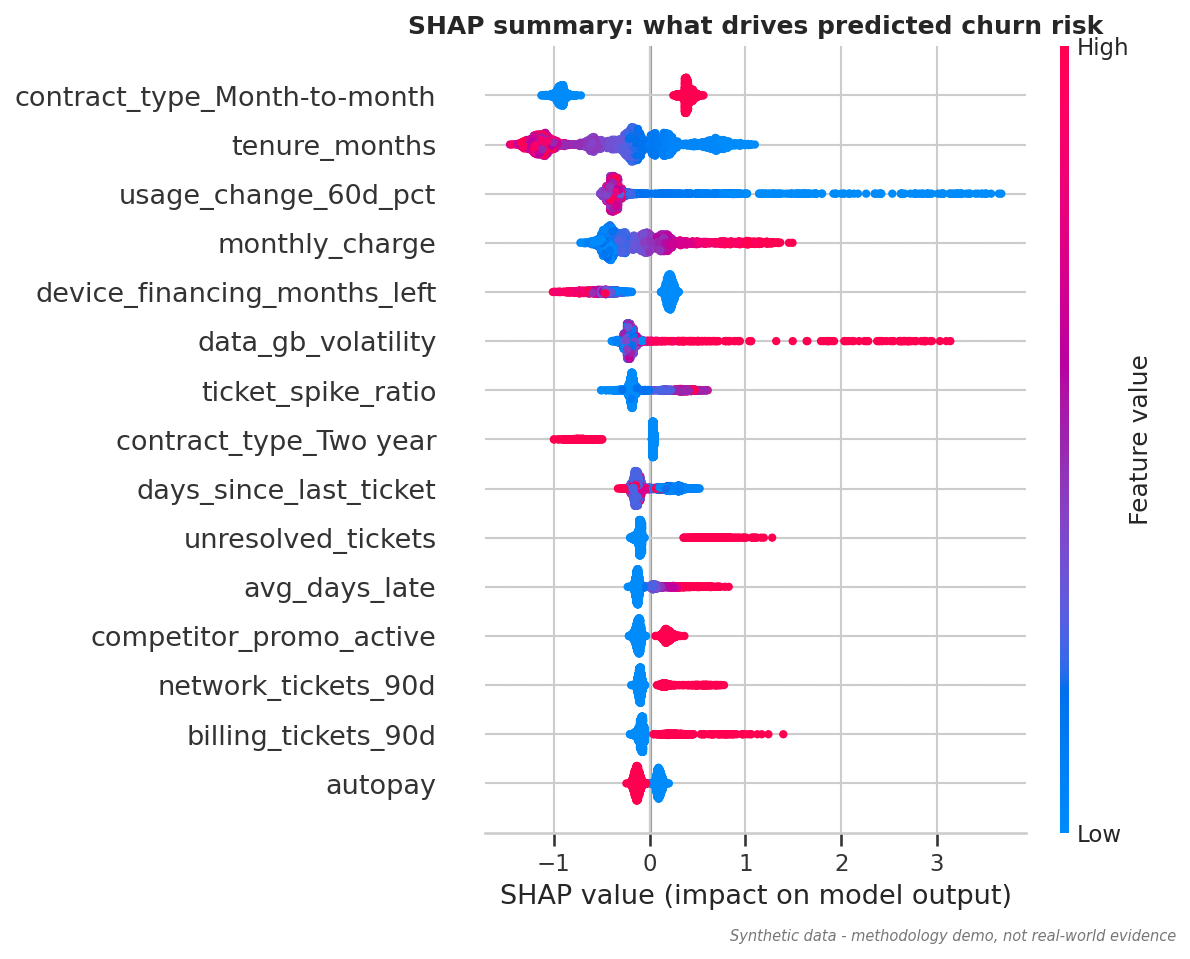

                  Unnamed: 0  mean_abs_shap
contract_type_Month-to-month          0.639
               tenure_months          0.530
        usage_change_60d_pct          0.468
              monthly_charge          0.334
device_financing_months_left          0.325
          data_gb_volatility          0.264
          ticket_spike_ratio          0.219
      contract_type_Two year          0.178
      days_since_last_ticket          0.163
          unresolved_tickets          0.147


In [3]:
display(Image(FIG / 'shap_summary.png'))
print(pd.read_csv(C.REPORTS / 'shap_importance.csv').head(10).round(3).to_string(index=False))

**Reading the SHAP plot.** Month-to-month contract, short tenure, falling data usage and a high monthly charge push risk up; remaining device financing and two-year contracts push it down (a contractual lock-in). Support signals (ticket spike ratio, unresolved tickets) and late payments add smaller but actionable increments. SHAP shows what the *model* uses; it is not proof of causation, and the offer response must be tested experimentally (section 5).

## 3. From scores to dollars: retention cost model
Assumptions (all illustrative, editable in `src/config.py`): contact cost $3 + offer cost $25 per contacted customer; 30% of contacted would-be churners accept and stay; a saved customer is worth monthly charge x 12 months x 40% margin.

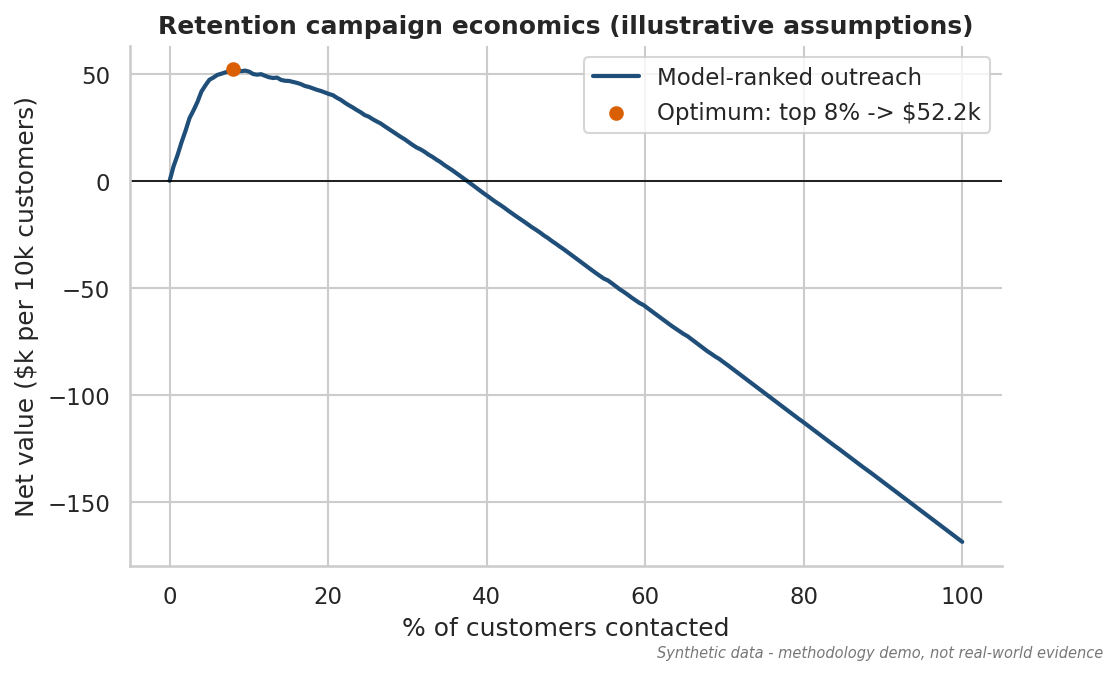

Optimal: contact top 8.0% (804 of 10,000)
Churners reached: 497 of 792 | precision of list: 61.8%
Expected net value: $52,182 | same budget, random targeting: $-13,548
Value-aware rule (p x save x value > cost): {'contacted': 900, 'contact_fraction': 0.09, 'net_value': 54075.21119999999}


In [4]:
display(Image(FIG / 'business_net_value_curve.png'))
bz = b['business']
print(f"Optimal: contact top {bz['optimal_contact_fraction']:.1%} ({bz['optimal_contacted']} of {bz['holdout_customers']:,})")
print(f"Churners reached: {bz['optimal_churners_reached']} of {bz['holdout_churners']} | precision of list: {bz['optimal_precision']:.1%}")
print(f"Expected net value: ${bz['optimal_net_value']:,.0f} | same budget, random targeting: ${bz['random_same_budget_net_value']:,.0f}")
print('Value-aware rule (p x save x value > cost):', bz['value_aware_rule'])

**Key point.** Model-ranked outreach to ~8% of customers yields about **$52k expected net value per 10,000 customers scored**, whereas contacting the same number of customers at random *loses* about $13.5k (precision of a random list is ~8%, below the ~33% break-even). The value-aware rule (contact when expected gain exceeds cost) lands in the same place (9% of customers, ~$54k), which is reassuring.

## 4. Sensitivity: how fragile is the business case?

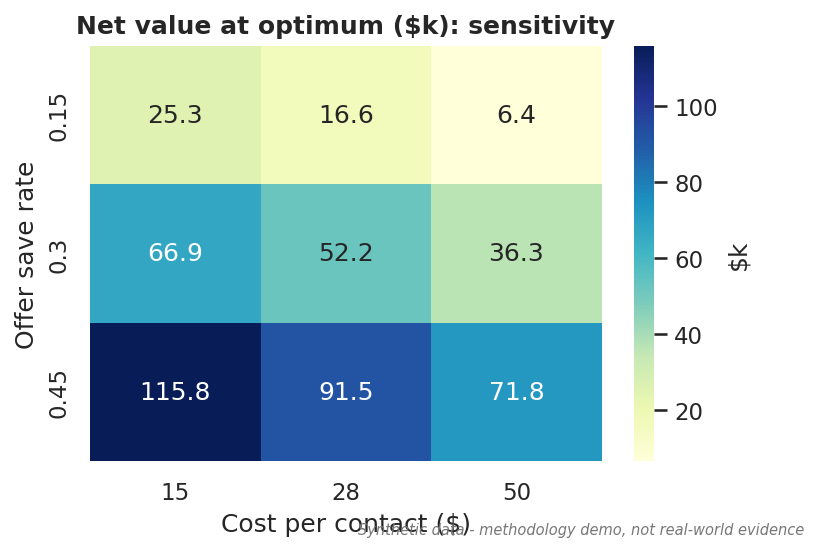

,save_rate,cost_per_contact,optimal_contact_fraction,net_value
0,0.15,15,0.080,25286.918
1,0.15,28,0.050,16627.190
2,0.15,50,0.040,6430.214
3,0.30,15,0.191,66917.198
4,0.30,28,0.080,52181.837
5,0.30,50,0.060,36334.469
6,0.45,15,0.206,115823.174
7,0.45,28,0.136,91510.969
8,0.45,50,0.080,71840.755


In [5]:
display(Image(FIG / 'business_sensitivity.png'))
display(pd.read_csv(C.REPORTS / 'sensitivity.csv').round(3))

Even in the pessimistic corner (15% save rate, $50 per contact) the campaign stays positive (~$6k), but the optimal list shrinks from ~20% to ~4% of customers. **The decision most sensitive to error is the save rate**, which we cannot learn from observational data - hence the experiment below.

## 5. A/B test design to validate the offer

In [6]:
from scipy.stats import norm
def n_per_arm(p0, rel_reduction, alpha=0.05, power=0.8):
    p1 = p0 * (1 - rel_reduction); pbar = (p0 + p1) / 2
    za, zb = norm.ppf(1 - alpha / 2), norm.ppf(power)
    return int(np.ceil(((za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2) / (p0 - p1) ** 2))
p0 = bz['optimal_precision']
for rr in (0.30, 0.20, 0.10):
    print(f'Detect {rr:.0%} relative churn reduction from baseline {p0:.1%}: {n_per_arm(p0, rr):,} customers per arm')

Detect 30% relative churn reduction from baseline 61.8%: 113 customers per arm
Detect 20% relative churn reduction from baseline 61.8%: 253 customers per arm
Detect 10% relative churn reduction from baseline 61.8%: 995 customers per arm


**Design.** Each month, take the model's top-risk list, randomly assign 50% to receive the offer and 50% to a holdout (no offer). Primary metric: 30-day churn. Guardrails: ARPU, offer cost, complaint rate. With ~62% baseline churn in the targeted list, detecting a 20% relative reduction needs only about a few hundred customers per arm, so a single monthly campaign is already informative. Keep a small *model-agnostic* random arm to measure the model's incremental value over rules.

## 6. Recommendations
1. **Target the top ~8-10% by calibrated risk** each month; exclude the bottom 30% of deciles.
2. **Tailor the offer to the driver:** month-to-month and short-tenure customers -> contract-upgrade discount; usage-drop customers -> plan right-sizing; ticket-burst or unresolved-ticket customers -> proactive service callback before any discount.
3. **Fix the early-life experience:** ~20% of 0-6 month customers churn; an onboarding programme is cheaper than late-stage saves.
4. **Run the A/B test before scaling**, and revisit the cost assumptions with Finance.
5. **Monitor drift** (PSI on key features, monthly PR-AUC) and retrain quarterly.

### Limitations
Synthetic data; planted effects are linear-ish and cleaner than reality; no time dimension for drift testing; cost-model inputs are assumptions; SHAP is associational.